## Oresund

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements, error_mshred

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

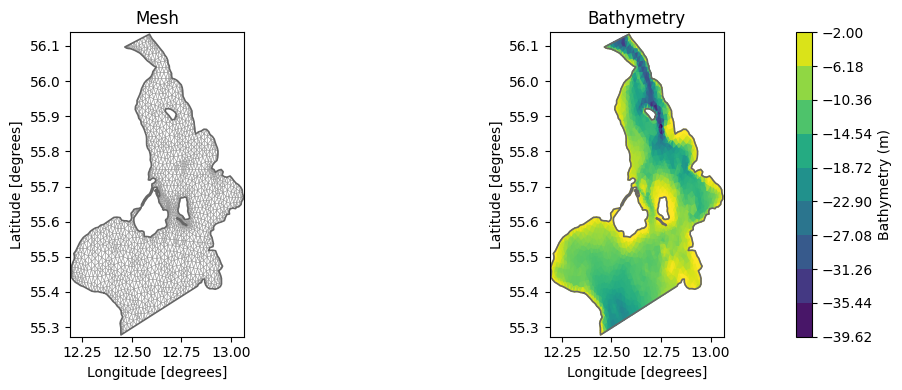

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

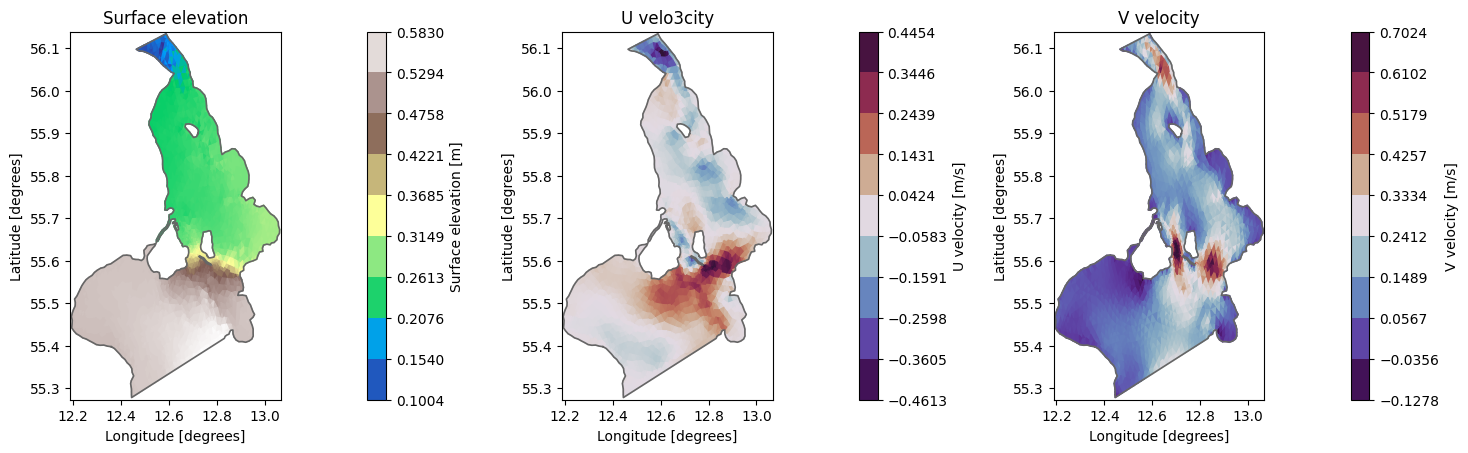

In [5]:
# plot a simulation
ds = dfs.read(time = slice("2021-01-01", "2023-12-30"))

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


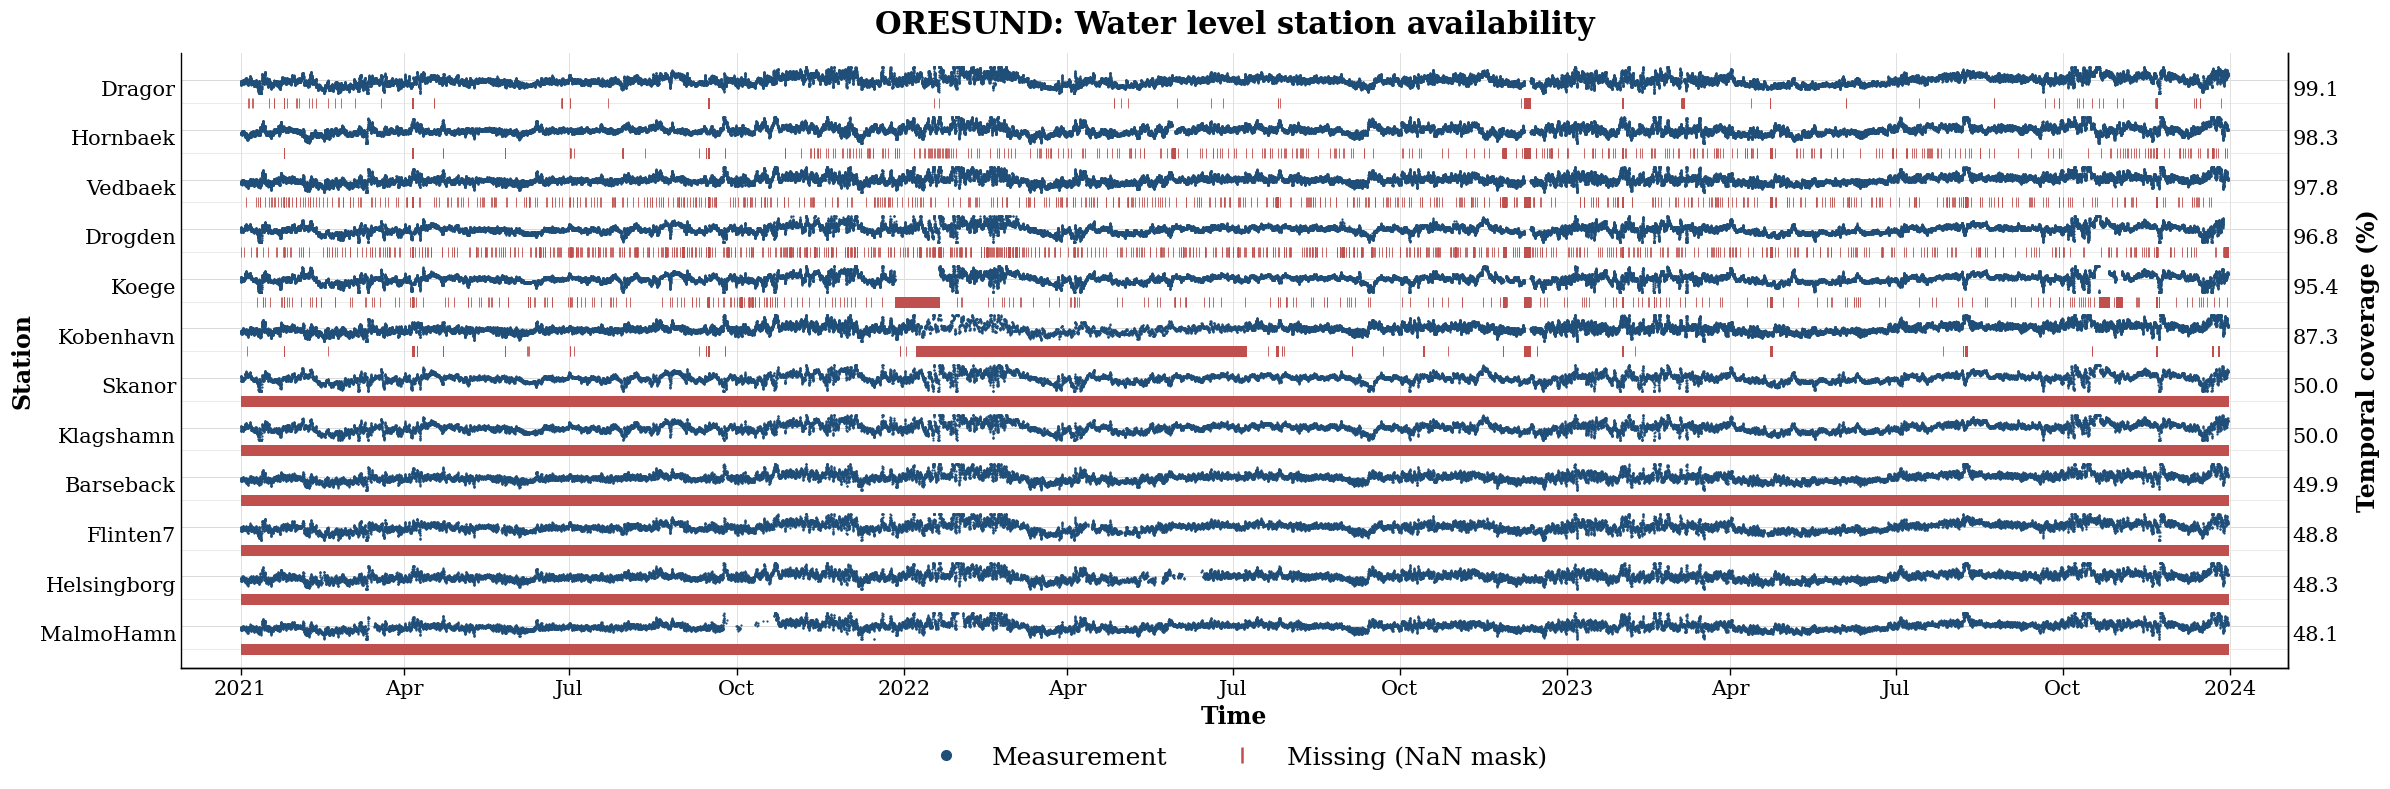

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D


def plot_station_availability(
    wllist,
    ds,
    row_h=0.26,           # half-height of the sensor trace
    sig_offset=0.14,      # sensor trace centre, above the slot centre
    mask_offset=-0.32,    # NaN mask position, below the slot centre
    marker_size=1.6,
    mask_marker_size=7.0,
    c_data="#1f4e79",     # blue: valid measurements
    c_nan="#c0504d",      # red: missing data (mask)
    figsize=(24, 8),
    font_scale=1.0,       # multiplies every font size (defaults tuned for 22x8)
    time_pad_frac=0.03,   # extra time horizon on each side, as a fraction of the span
    xlim=None,            # optional (start, end) to override the time range
    savepath=None,
    dpi=300,
):
    """
    Plot water-level station availability against the simulation timeline.

    Each station occupies one slot made of two sub-rows:
      - top: the sensor stream (blue dots, one per valid measurement);
      - bottom: a mask strip with a red tick wherever the station has no data (NaN).

    Parameters
    ----------
    wllist : list
        Observation objects with .name, .time and .values attributes.
    ds : xarray.Dataset
        Model output with a `time` coordinate.
    row_h : float
        Half-height of the sensor trace (in slot units).
    sig_offset, mask_offset : float
        Vertical position of the sensor trace / NaN mask relative to the slot centre.
    marker_size, mask_marker_size : float
        Marker sizes (points) for the sensor dots / mask ticks.
    c_data, c_nan : str
        Colours for valid / missing samples.
    figsize : tuple
        Figure size in inches.
    font_scale : float
        Global multiplier for all font sizes.
    time_pad_frac : float
        Widens the time axis by this fraction of the simulation span on each side.
    xlim : tuple or None
        Explicit (start, end) for the time axis; overrides `time_pad_frac`.
    savepath : str or None
        If given, the figure is saved there (e.g. "station_availability.pdf").
    dpi : int
        Resolution used for rasterized traces when saving.

    Returns
    -------
    fig, ax, coverage_pct_by_name
    """
    fs = lambda x: x * font_scale

    # ---- coverage against the simulation timeline ----
    model_time = pd.DatetimeIndex(ds.time)
    coverage_pct_by_name = {}
    series_by_name = {}
    for obs in wllist:
        s = pd.Series(np.asarray(obs.values).ravel(), index=pd.DatetimeIndex(obs.time))
        s = s[~s.index.duplicated()]
        s = s.reindex(model_time)                     # NaN where no data
        series_by_name[obs.name] = s
        coverage_pct_by_name[obs.name] = 100.0 * s.notna().sum() / len(model_time)

    # lowest coverage at the bottom, highest at the top
    wllist_sorted = sorted(wllist, key=lambda o: coverage_pct_by_name.get(o.name, 0.0))
    n = len(wllist_sorted)

    # ---- time axis limits (widened horizon) ----
    if xlim is not None:
        t0, t1 = pd.Timestamp(xlim[0]), pd.Timestamp(xlim[1])
    else:
        span = model_time[-1] - model_time[0]
        t0 = model_time[0] - span * time_pad_frac
        t1 = model_time[-1] + span * time_pad_frac

    # ---- paper-style plot ----
    rc = {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "axes.linewidth": 1.0,
        "xtick.direction": "out",
        "xtick.major.width": 1.0,
        "xtick.major.size": 5,
    }

    with plt.rc_context(rc):
        fig, ax = plt.subplots(figsize=figsize)

        for i, obs in enumerate(wllist_sorted):
            s = series_by_name[obs.name]
            mask = s.notna().values
            y_sig = i + sig_offset
            y_mask = i + mask_offset

            # baselines: sensor zero line and mask strip
            ax.axhline(y_sig, color="0.85", lw=0.7, zorder=0)
            ax.axhline(y_mask, color="0.92", lw=0.7, zorder=0)

            # --- sensor stream: blue dots, centred on the sub-row and scaled ---
            if mask.any():
                valid = s[mask]
                vals = valid - valid.mean()
                scale = np.percentile(np.abs(vals.values), 99)
                scale = scale if np.isfinite(scale) and scale > 0 else 1.0
                y = y_sig + np.clip(vals.values / scale, -1, 1) * row_h

                ax.plot(
                    valid.index, y,
                    linestyle="none", marker="o", ms=marker_size, mew=0,
                    color=c_data, zorder=2, rasterized=True,
                )

            # --- NaN mask: red ticks below the sensor ---
            if (~mask).any():
                ax.plot(
                    s.index[~mask], np.full((~mask).sum(), y_mask),
                    linestyle="none", marker="|", ms=mask_marker_size, mew=0.6,
                    color=c_nan, zorder=1, rasterized=True,
                )

        ax.set_ylim(-0.7, n - 0.3)
        ax.set_xlim(t0, t1)

        # readable date ticks on a wide axis
        locator = mdates.AutoDateLocator(minticks=8, maxticks=16)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

        # left labels: station name
        ax.set_yticks(range(n))
        ax.set_yticklabels([o.name for o in wllist_sorted], fontsize=fs(15))
        ax.set_ylabel("Station", fontsize=fs(17), fontweight="bold")

        # right labels: coverage %
        ax2 = ax.twinx()
        ax2.set_ylim(ax.get_ylim())
        ax2.set_yticks(range(n))
        ax2.set_yticklabels(
            [f"{coverage_pct_by_name[o.name]:.1f}" for o in wllist_sorted], fontsize=fs(15)
        )
        ax2.set_ylabel("Temporal coverage (%)", fontsize=fs(17), labelpad=12, fontweight="bold")

        ax.set_xlabel("Time", fontsize=fs(17), fontweight="bold")
        ax.tick_params(axis="x", labelsize=fs(15))
        ax.tick_params(axis="y", length=0)
        ax2.tick_params(axis="y", length=0)
        ax.grid(axis="x", color="0.88", lw=0.7)
        ax.set_axisbelow(True)
        for a in (ax, ax2):
            a.spines["top"].set_visible(False)
        ax2.spines["left"].set_visible(False)

        ax.set_title(
            "ORESUND: Water level station availability",
            fontsize=fs(22), pad=14, fontweight="bold",
        )

        # legend
        ax.legend(
            handles=[
                Line2D([0], [0], marker="o", ls="none", color=c_data, ms=7, label="Measurement"),
                Line2D([0], [0], marker="|", ls="none", color=c_nan, ms=12, mew=1.8, label="Missing (NaN mask)"),
            ],
            loc="upper center", bbox_to_anchor=(0.5, -0.09),
            ncol=2, frameon=False, fontsize=fs(18),
        )

        fig.tight_layout()
        if savepath:
            fig.savefig(savepath, bbox_inches="tight", dpi=dpi)
        plt.show()

    return fig, ax, coverage_pct_by_name


# Uso:
wllist = get_wl_point_obs()
fig, ax, cov = plot_station_availability(wllist, ds, savepath="station_availability.pdf")

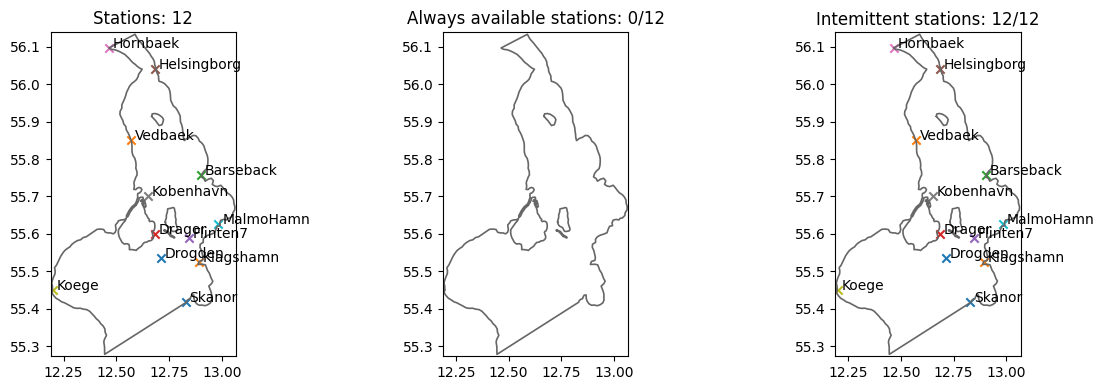

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)
print("\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# inputs
measurements = torch.as_tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes


Measurements shape: (52512, 12)

H shape: torch.Size([52512, 3320])
U shape: torch.Size([52512, 3320])
V shape: torch.Size([52512, 3320])
Measurements shape: torch.Size([52512, 12])


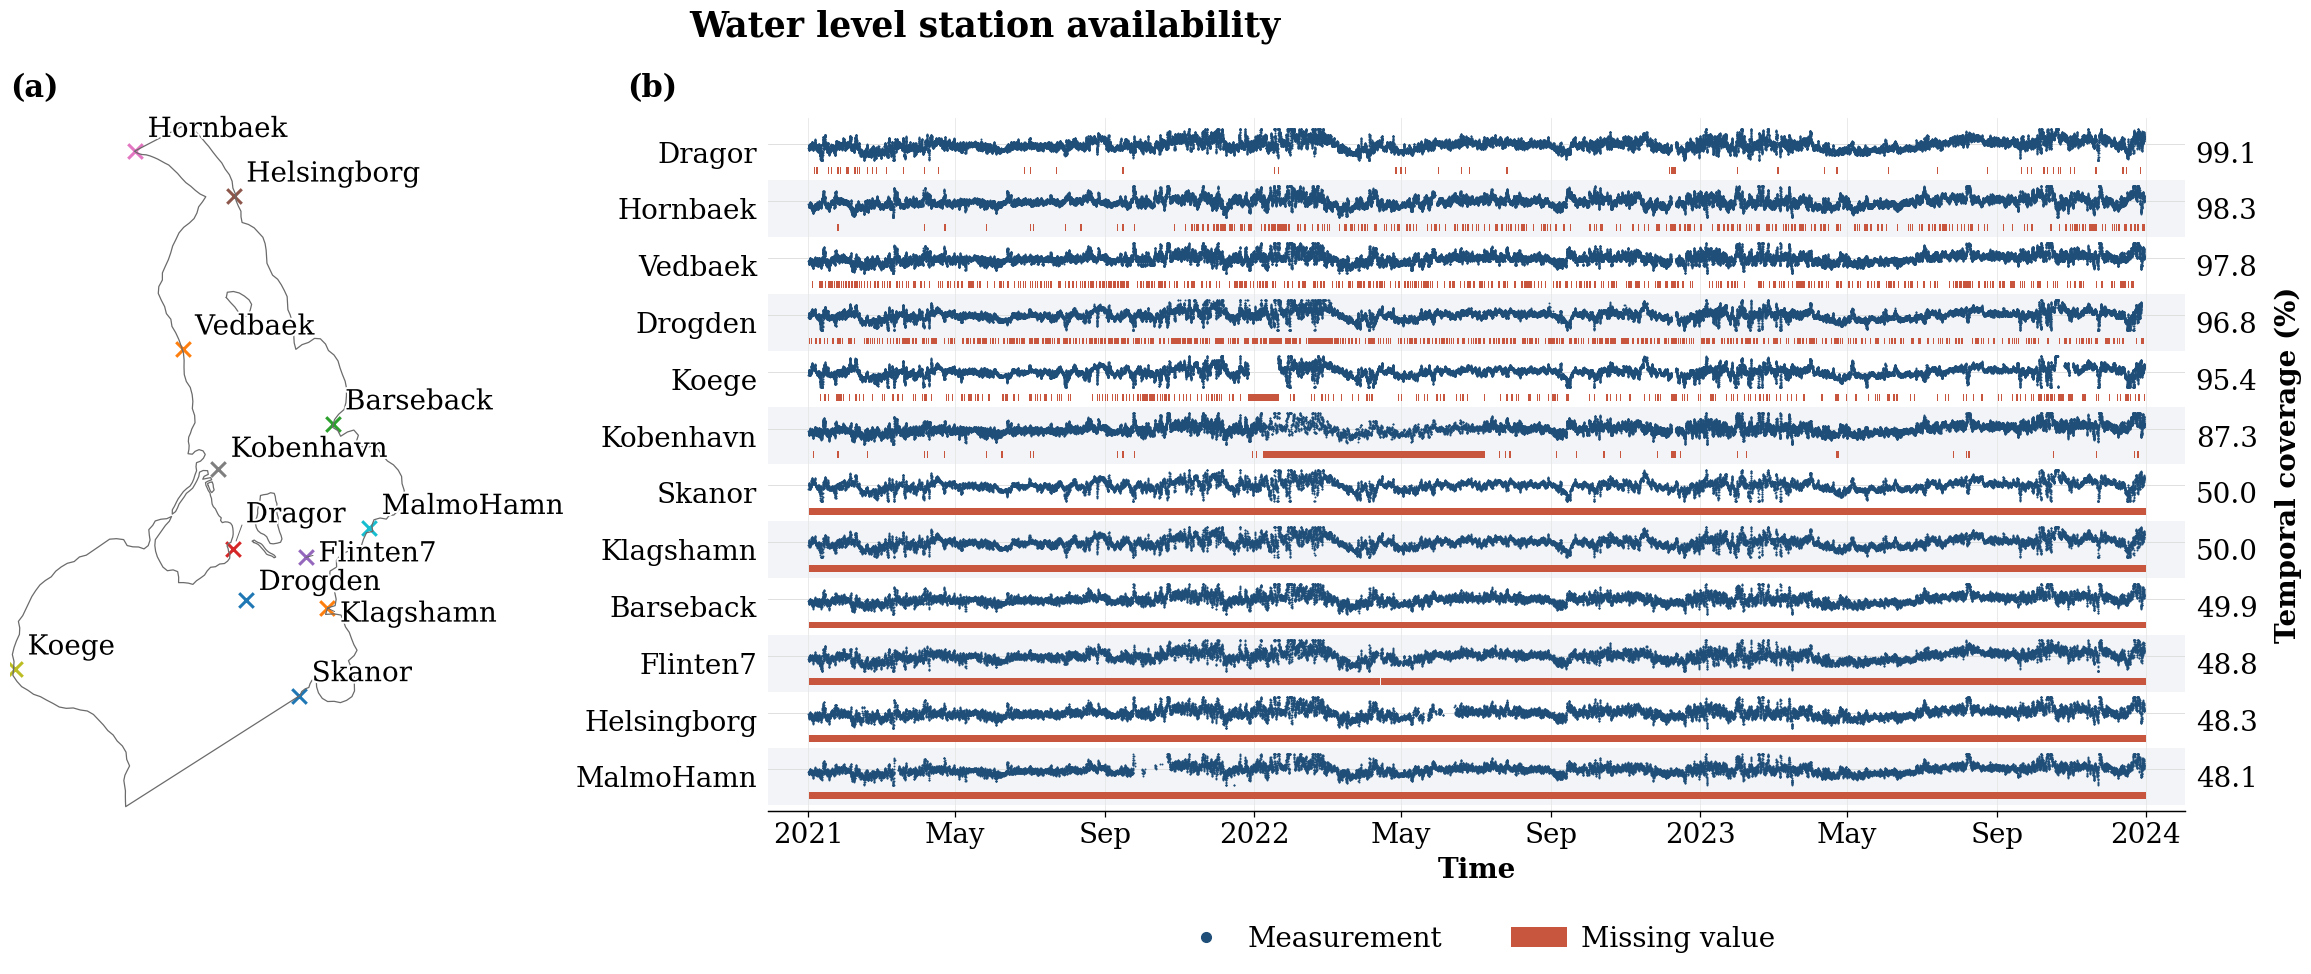

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.collections import PathCollection
from matplotlib.text import Text
import modelskill as ms  # used by the spatial overview panel


# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "xtick.major.width": 0.9,
    "xtick.major.size": 4,
    "pdf.fonttype": 42,        # embed TrueType fonts (journals like this)
    "ps.fonttype": 42,
}

C_DATA = "#1f4e79"      # valid measurements
C_NAN = "#c8553d"       # missing data
C_BAND = "#f2f4f7"      # alternating row band
C_LAND = "#e9e6df"      # map land fill
C_COAST = "#6b6b6b"     # map coastline
C_MARK = "#1f4e79"      # map station markers


def plot_station_availability(
    wllist,
    ds,
    ax=None,
    row_h=0.27,            # half-height of the sensor trace
    sig_offset=0.13,       # sensor trace centre, above the slot centre
    mask_offset=-0.33,     # NaN mask position, below the slot centre
    mask_h=0.12,           # thickness of the missing-data bars
    marker_size=1.4,
    c_data=C_DATA,
    c_nan=C_NAN,
    figsize=(30,10),
    font_scale=1.0,
    time_pad_frac=0.03,
    xlim=None,
    show_title=True,
    panel_label=None,      # e.g. "(b)"
    savepath=None,
    dpi=300,
):
    """
    Water-level station availability against the simulation timeline.

    Each station occupies one slot: the sensor stream (dots, demeaned and
    scaled per station) on top, and a strip of red bars below marking gaps.

    Returns
    -------
    fig, ax, coverage_pct_by_name
    """
    fs = lambda x: x * font_scale

    # ---- coverage against the simulation timeline ----
    model_time = pd.DatetimeIndex(ds.time)
    coverage_pct_by_name = {}
    series_by_name = {}
    for obs in wllist:
        s = pd.Series(np.asarray(obs.values).ravel(), index=pd.DatetimeIndex(obs.time))
        s = s[~s.index.duplicated()]
        s = s.reindex(model_time)                     # NaN where no data
        series_by_name[obs.name] = s
        coverage_pct_by_name[obs.name] = 100.0 * s.notna().sum() / len(model_time)

    # lowest coverage at the bottom, highest at the top
    wllist_sorted = sorted(wllist, key=lambda o: coverage_pct_by_name.get(o.name, 0.0))
    n = len(wllist_sorted)

    # ---- time axis limits ----
    if xlim is not None:
        t0, t1 = pd.Timestamp(xlim[0]), pd.Timestamp(xlim[1])
    else:
        span = model_time[-1] - model_time[0]
        t0 = model_time[0] - span * time_pad_frac
        t1 = model_time[-1] + span * time_pad_frac

    standalone = ax is None

    with plt.rc_context(PAPER_RC):
        if standalone:
            fig, ax = plt.subplots(figsize=figsize)
        else:
            fig = ax.figure

        for i, obs in enumerate(wllist_sorted):
            s = series_by_name[obs.name]
            mask = s.notna().values
            y_sig, y_mask = i + sig_offset, i + mask_offset

            if i % 2 == 0:
                ax.axhspan(i - 0.5, i + 0.5, color=C_BAND, zorder=-2, lw=0)

            ax.axhline(y_sig, color="0.86", lw=0.6, zorder=0)

            # --- sensor stream ---
            if mask.any():
                valid = s[mask]
                vals = valid - valid.mean()
                scale = np.percentile(np.abs(vals.values), 99)
                scale = scale if np.isfinite(scale) and scale > 0 else 1.0
                y = y_sig + np.clip(vals.values / scale, -1, 1) * row_h
                ax.plot(
                    valid.index, y, linestyle="none", marker="o",
                    ms=marker_size, mew=0, color=c_data, zorder=2, rasterized=True,
                )

            # --- missing data: contiguous gaps as bars ---
            if (~mask).any():
                idx = s.index
                dt = idx[1] - idx[0]
                miss = (~mask).astype(int)
                edges = np.diff(np.concatenate([[0], miss, [0]]))
                starts = np.where(edges == 1)[0]
                ends = np.where(edges == -1)[0]          # exclusive
                x0 = mdates.date2num(idx[starts])
                x1 = mdates.date2num(idx[ends - 1] + dt)
                min_w = (mdates.date2num(t1) - mdates.date2num(t0)) * 0.0008
                widths = np.maximum(x1 - x0, min_w)
                ax.broken_barh(
                    list(zip(x0, widths)), (y_mask - mask_h / 2, mask_h),
                    facecolors=c_nan, edgecolors="none", zorder=1, rasterized=True,
                )

        ax.set_ylim(-0.6, n - 0.4)
        ax.set_xlim(t0, t1)

        # ---- x axis ----
        locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.tick_params(axis="x", labelsize=fs(20), pad=4)
        ax.set_xlabel("Time", fontsize=fs(20), labelpad=6,fontweight="bold")

        # ---- left labels: station names ----
        ax.set_yticks(range(n))
        ax.set_yticklabels([o.name for o in wllist_sorted], fontsize=fs(20))
        ax.tick_params(axis="y", length=0, pad=8)

        # ---- right labels: coverage % ----
        ax2 = ax.twinx()
        ax2.set_ylim(ax.get_ylim())
        ax2.set_yticks(range(n))
        ax2.set_yticklabels(
            [f"{coverage_pct_by_name[o.name]:.1f}" for o in wllist_sorted],
            fontsize=fs(20),
        )
        ax2.tick_params(axis="y", length=0, pad=8)
        ax2.set_ylabel("Temporal coverage (%)", fontsize=fs(20), labelpad=12,
                       fontweight="bold")

        ax.grid(axis="x", color="0.9", lw=0.6)
        ax.set_axisbelow(True)
        for a in (ax, ax2):
            for side in ("top", "left", "right"):
                a.spines[side].set_visible(False)

        if panel_label:
            ax.text(
                -0.30, 1.02, panel_label, transform=ax.transAxes,
                fontsize=fs(20), fontweight="bold", va="bottom", ha="left",
            )
        if standalone and show_title:
            ax.set_title("Water level station availability",
                         fontsize=fs(20), pad=14, fontweight="bold")

        # ---- legend ----
        ax.legend(
            handles=[
                Line2D([0], [0], marker="o", ls="none", color=c_data, ms=7,
                       label="Measurement"),
                Patch(facecolor=c_nan, edgecolor="none", label="Missing value"),
            ],
            loc="upper center", bbox_to_anchor=(0.5, -0.13),
            ncol=2, frameon=False, fontsize=fs(20), handletextpad=0.5,
            columnspacing=2.5,
        )

        if standalone:
            fig.tight_layout()
            if savepath:
                fig.savefig(savepath, bbox_inches="tight", dpi=dpi)
            plt.show()

    return fig, ax, coverage_pct_by_name


# ------------------------------------------------------------------
# Map helpers
# ------------------------------------------------------------------
def _style_map(ax, stations, fs):
    """Soften the coastline and enlarge the markers."""
    # soften coastline
    for line in ax.lines:
        if line.get_marker() in (None, "None", "", " "):
            line.set_color(C_COAST)
            line.set_linewidth(0.9)

    # bigger markers (original per-station colours kept)
    for line in ax.lines:
        if line.get_marker() not in (None, "None", "", " "):
            line.set_markersize(fs(11))
            line.set_markeredgewidth(2.2)
    for coll in ax.collections:
        if isinstance(coll, PathCollection):
            coll.set_sizes([fs(110)])
            coll.set_linewidths(2.2)


def _place_map_labels(ax, stations, fontsize=20, offset=(9, 6), pad=3.0, max_iter=500):
    """
    Station names on the map, without overlaps (white halo for legibility).
    Labels are pushed apart vertically; a leader line is drawn only for
    labels that had to move noticeably.
    """
    fig = ax.figure
    try:
        pts = [(st.name, float(st.x), float(st.y)) for st in stations]
    except Exception:
        for txt in ax.texts:
            txt.set_fontsize(fontsize)
        return

    for txt in list(ax.texts):
        txt.remove()

    halo = [pe.withStroke(linewidth=3.0, foreground="white")]
    k = fig.dpi / 72.0
    anns = [
        ax.annotate(
            name, xy=(x, y), xytext=offset, textcoords="offset points",
            fontsize=fontsize, ha="left", va="bottom", zorder=6,
            path_effects=halo,
            arrowprops=dict(arrowstyle="-", color="0.4", lw=0.7,
                            shrinkA=2, shrinkB=6, relpos=(0, 0.5)),
        )
        for name, x, y in pts
    ]
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    n = len(anns)
    anchor = np.array([ax.transData.transform((x, y)) for _, x, y in pts])
    size = np.array([
        [b.width, b.height]
        for b in (Text.get_window_extent(a, renderer) for a in anns)
    ])
    off0 = np.tile(np.array(offset, float) * k, (n, 1))
    off = off0.copy()
    marker_r = 8.0 * k

    def box(i):
        x0, y0 = anchor[i] + off[i]
        return x0, y0, x0 + size[i, 0], y0 + size[i, 1]

    for _ in range(max_iter):
        moved = False
        for i in range(n):
            xi0, yi0, xi1, yi1 = box(i)
            for j in range(i + 1, n):
                xj0, yj0, xj1, yj1 = box(j)
                ov_x = min(xi1, xj1) - max(xi0, xj0) + pad * k
                ov_y = min(yi1, yj1) - max(yi0, yj0) + pad * k
                if ov_x > 0 and ov_y > 0:
                    step = ov_y / 2 + 0.5
                    if (yi0 + yi1) >= (yj0 + yj1):
                        off[i, 1] += step
                        off[j, 1] -= step
                    else:
                        off[i, 1] -= step
                        off[j, 1] += step
                    moved = True
                    xi0, yi0, xi1, yi1 = box(i)
            for j in range(n):
                if j == i:
                    continue
                mx, my = anchor[j]
                ov_x = min(xi1, mx + marker_r) - max(xi0, mx - marker_r)
                ov_y = min(yi1, my + marker_r) - max(yi0, my - marker_r)
                if ov_x > 0 and ov_y > 0:
                    direction = 1.0 if (yi0 + yi1) / 2 >= my else -1.0
                    off[i, 1] += direction * (ov_y + 1.0)
                    moved = True
                    xi0, yi0, xi1, yi1 = box(i)
        if not moved:
            break

    for a, o, o_init in zip(anns, off, off0):
        a.xyann = (o[0] / k, o[1] / k)
        a.arrow_patch.set_visible(bool(np.hypot(*(o - o_init)) > 6 * k))


# ------------------------------------------------------------------
# Combined figure
# ------------------------------------------------------------------
def plot_overview_and_availability(
    stations,
    msh,
    wllist,
    ds,
    figsize=(30, 9),
    font_scale=1.0,
    width_ratios=(0.33, 0.67),
    wspace=0.36,
    panel_labels=False,        # optional (a) / (b)
    title="Water level station availability",
    savepath=None,
    dpi=300,
    **avail_kwargs,            # forwarded to plot_station_availability
):
    """
    Left: spatial overview of the stations. Right: availability timeline.

    Returns
    -------
    fig, axs, coverage_pct_by_name
    """
    fs = lambda x: x * font_scale

    with plt.rc_context(PAPER_RC):
        fig = plt.figure(figsize=figsize)
        gs = fig.add_gridspec(1, 2, width_ratios=width_ratios, wspace=wspace)
        axs = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]

        # ---- left: map ----
        ms.plotting.spatial_overview(
            stations, mod=msh.geometry, ax=axs[0], title="",
        )
        axs[0].set_title("")
        axs[0].set_axis_off()
        _style_map(axs[0], stations, fs)

        # ---- right: availability ----
        _, _, cov = plot_station_availability(
            wllist, ds, ax=axs[1], font_scale=font_scale, **avail_kwargs
        )
        axs[1].set_title("")

        _place_map_labels(axs[0], stations, fontsize=fs(20))

        if panel_labels:
            axs[0].text(0.0, 1.02, "(a)", transform=axs[0].transAxes,
                        fontsize=fs(22), fontweight="bold", va="bottom", ha="left")
            axs[1].text(-0.10, 1.02, "(b)", transform=axs[1].transAxes,
                        fontsize=fs(22), fontweight="bold", va="bottom", ha="left")
        if title:
            fig.suptitle(title, fontsize=fs(25), fontweight="bold", x=0.5, y=1.0)

        if savepath:
            fig.savefig(savepath, bbox_inches="tight", dpi=dpi)
        plt.show()

    return fig, axs, cov

wllist = get_wl_point_obs()
fig, axs, cov = plot_overview_and_availability(
    stations, msh, wllist, ds,
    savepath="station_overview_availability.pdf", panel_labels=True, title="Water level station availability", wspace=0.2
)


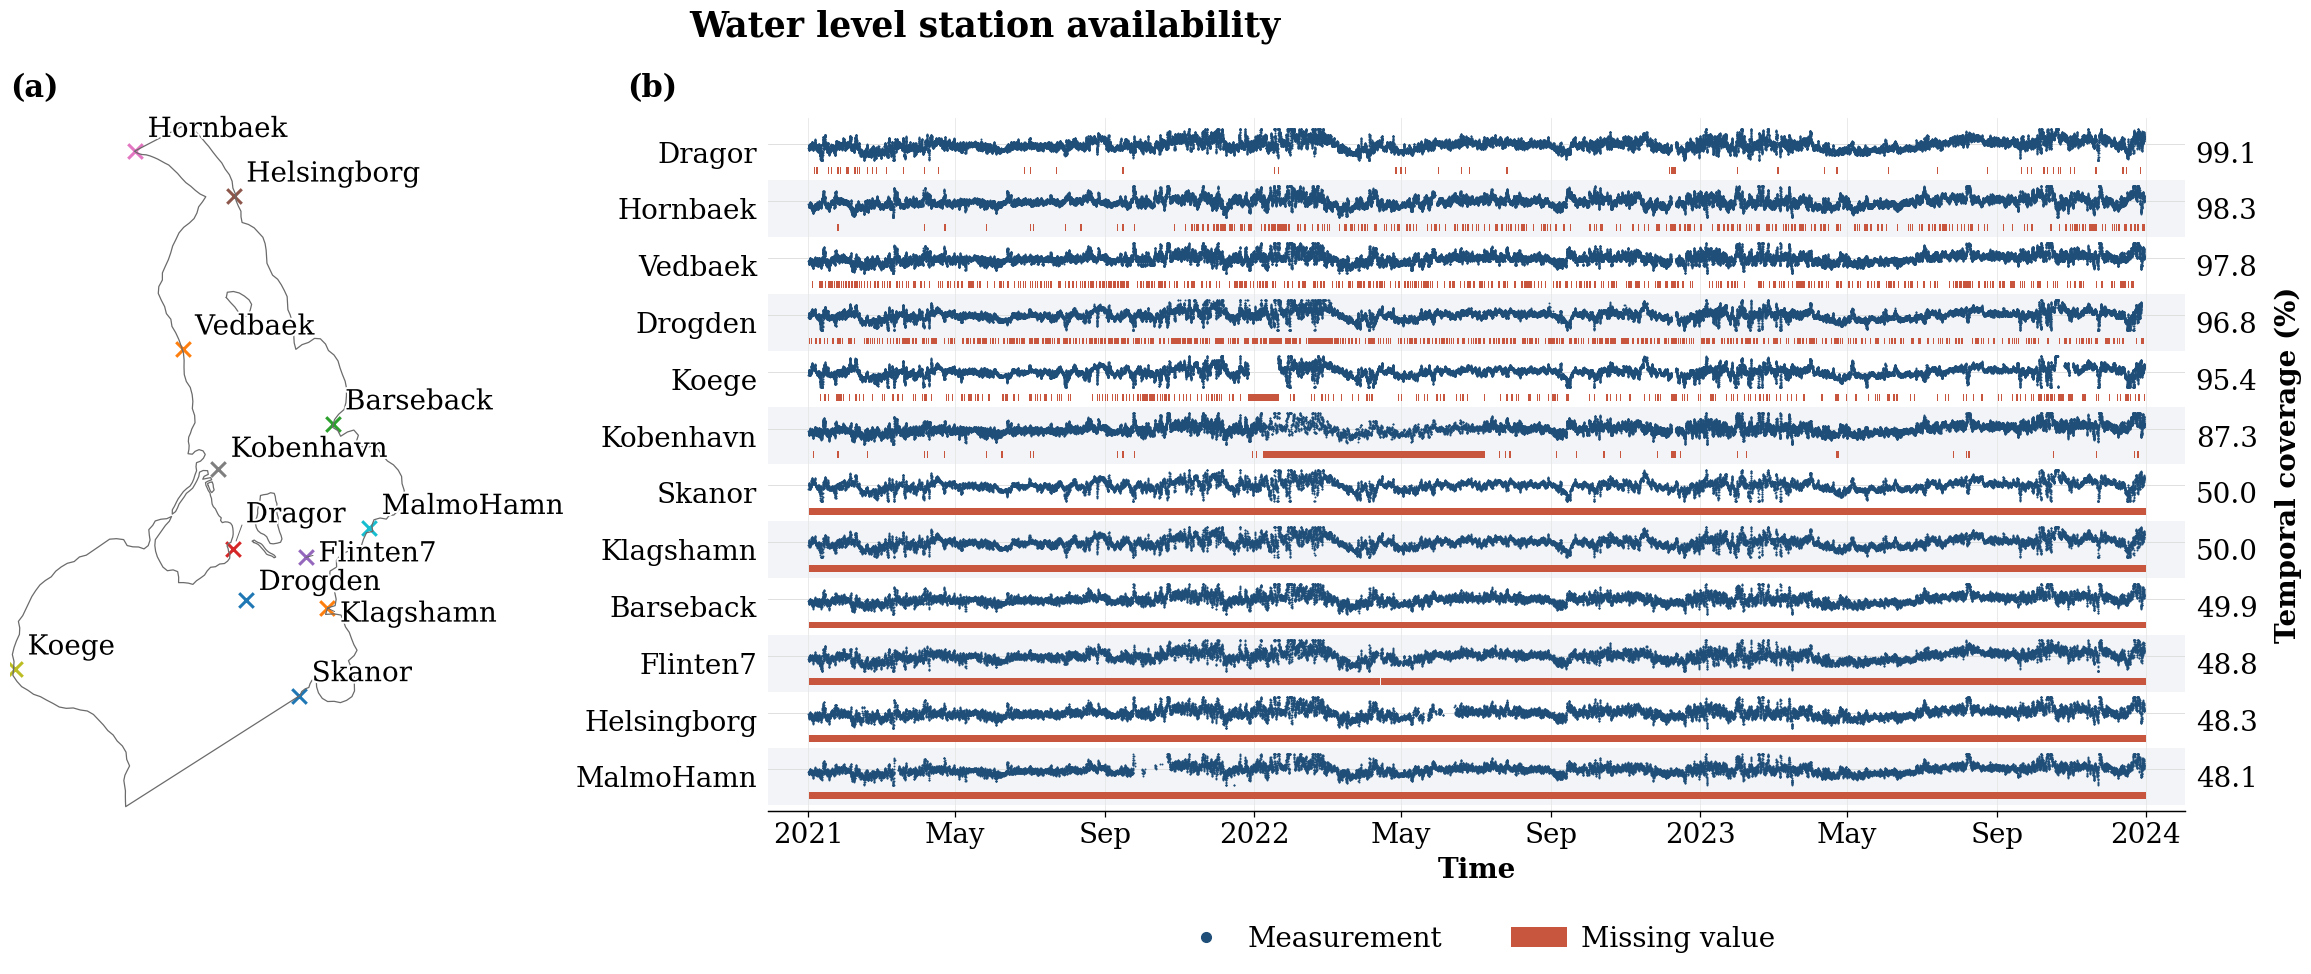

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.collections import PathCollection
from matplotlib.text import Text
import modelskill as ms


# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "xtick.major.width": 0.9,
    "xtick.major.size": 4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

C_DATA = "#1f4e79"      # valid measurements
C_NAN = "#c8553d"       # missing data
C_BAND = "#f2f4f7"      # alternating row band
C_LAND = "#e9e6df"      # map land fill
C_COAST = "#6b6b6b"     # map coastline
C_MARK = "#1f4e79"      # map station markers


# ------------------------------------------------------------------
# Station availability plot
# ------------------------------------------------------------------
def plot_station_availability(
    wllist,
    ds,
    ax=None,
    row_h=0.27,
    sig_offset=0.13,
    mask_offset=-0.33,
    mask_h=0.12,
    marker_size=1.4,
    c_data=C_DATA,
    c_nan=C_NAN,
    figsize=(30, 10),
    font_scale=1.0,
    time_pad_frac=0.03,
    xlim=None,
    show_title=True,
    panel_label=None,
    savepath=None,
    dpi=600,
):
    """
    Water-level station availability against the simulation timeline.

    Each station occupies one slot:
      - sensor stream: blue dots
      - missing data: red bars

    Returns
    -------
    fig, ax, coverage_pct_by_name
    """

    fs = lambda x: x * font_scale

    # --------------------------------------------------------------
    # Coverage against the simulation timeline
    # --------------------------------------------------------------
    model_time = pd.DatetimeIndex(ds.time)

    coverage_pct_by_name = {}
    series_by_name = {}

    for obs in wllist:

        s = pd.Series(
            np.asarray(obs.values).ravel(),
            index=pd.DatetimeIndex(obs.time),
        )

        # Remove duplicated timestamps
        s = s[~s.index.duplicated()]

        # Align observations to simulation timeline
        s = s.reindex(model_time)

        series_by_name[obs.name] = s

        coverage_pct_by_name[obs.name] = (
            100.0 * s.notna().sum() / len(model_time)
        )

    # Lowest coverage at bottom, highest at top
    wllist_sorted = sorted(
        wllist,
        key=lambda o: coverage_pct_by_name.get(o.name, 0.0),
    )

    n = len(wllist_sorted)

    # --------------------------------------------------------------
    # Time axis limits
    # --------------------------------------------------------------
    if xlim is not None:

        t0 = pd.Timestamp(xlim[0])
        t1 = pd.Timestamp(xlim[1])

    else:

        span = model_time[-1] - model_time[0]

        t0 = model_time[0] - span * time_pad_frac
        t1 = model_time[-1] + span * time_pad_frac

    standalone = ax is None

    with plt.rc_context(PAPER_RC):

        if standalone:

            fig, ax = plt.subplots(figsize=figsize)

        else:

            fig = ax.figure

        # ----------------------------------------------------------
        # Stations
        # ----------------------------------------------------------
        for i, obs in enumerate(wllist_sorted):

            s = series_by_name[obs.name]

            mask = s.notna().values

            y_sig = i + sig_offset
            y_mask = i + mask_offset

            # Alternating background
            if i % 2 == 0:

                ax.axhspan(
                    i - 0.5,
                    i + 0.5,
                    color=C_BAND,
                    zorder=-2,
                    lw=0,
                )

            # Horizontal guide line
            ax.axhline(
                y_sig,
                color="0.86",
                lw=0.6,
                zorder=0,
            )

            # ------------------------------------------------------
            # Sensor stream
            # ------------------------------------------------------
            if mask.any():

                valid = s[mask]

                vals = valid - valid.mean()

                scale = np.percentile(
                    np.abs(vals.values),
                    99,
                )

                if not np.isfinite(scale) or scale <= 0:
                    scale = 1.0

                y = (
                    y_sig
                    + np.clip(
                        vals.values / scale,
                        -1,
                        1,
                    ) * row_h
                )

                ax.plot(
                    valid.index,
                    y,
                    linestyle="none",
                    marker="o",
                    ms=marker_size,
                    mew=0,
                    color=c_data,
                    zorder=2,
                    rasterized=True,
                )

            # ------------------------------------------------------
            # Missing data
            # ------------------------------------------------------
            if (~mask).any():

                idx = s.index

                dt = idx[1] - idx[0]

                miss = (~mask).astype(int)

                edges = np.diff(
                    np.concatenate(
                        [[0], miss, [0]]
                    )
                )

                starts = np.where(edges == 1)[0]

                ends = np.where(edges == -1)[0]

                x0 = mdates.date2num(
                    idx[starts]
                )

                x1 = mdates.date2num(
                    idx[ends - 1] + dt
                )

                min_w = (
                    mdates.date2num(t1)
                    - mdates.date2num(t0)
                ) * 0.0008

                widths = np.maximum(
                    x1 - x0,
                    min_w,
                )

                ax.broken_barh(
                    list(zip(x0, widths)),
                    (
                        y_mask - mask_h / 2,
                        mask_h,
                    ),
                    facecolors=c_nan,
                    edgecolors="none",
                    zorder=1,
                    rasterized=True,
                )

        # ----------------------------------------------------------
        # Y limits
        # ----------------------------------------------------------
        ax.set_ylim(
            -0.6,
            n - 0.4,
        )

        # ----------------------------------------------------------
        # X limits
        # ----------------------------------------------------------
        ax.set_xlim(
            t0,
            t1,
        )

        # ----------------------------------------------------------
        # X axis
        # ----------------------------------------------------------
        locator = mdates.AutoDateLocator(
            minticks=6,
            maxticks=12,
        )

        ax.xaxis.set_major_locator(locator)

        ax.xaxis.set_major_formatter(
            mdates.ConciseDateFormatter(locator)
        )

        ax.tick_params(
            axis="x",
            labelsize=fs(20),
            pad=4,
        )

        ax.set_xlabel(
            "Time",
            fontsize=fs(20),
            labelpad=6,
            fontweight="bold",
        )

        # ----------------------------------------------------------
        # Left labels: station names
        # ----------------------------------------------------------
        ax.set_yticks(
            range(n)
        )

        ax.set_yticklabels(
            [
                o.name
                for o in wllist_sorted
            ],
            fontsize=fs(20),
        )

        ax.tick_params(
            axis="y",
            length=0,
            pad=8,
        )

        # ----------------------------------------------------------
        # Right labels: temporal coverage
        # ----------------------------------------------------------
        ax2 = ax.twinx()

        ax2.set_ylim(
            ax.get_ylim()
        )

        ax2.set_yticks(
            range(n)
        )

        ax2.set_yticklabels(
            [
                f"{coverage_pct_by_name[o.name]:.1f}"
                for o in wllist_sorted
            ],
            fontsize=fs(20),
        )

        ax2.tick_params(
            axis="y",
            length=0,
            pad=8,
        )

        ax2.set_ylabel(
            "Temporal coverage (%)",
            fontsize=fs(20),
            labelpad=12,
            fontweight="bold",
        )

        # ----------------------------------------------------------
        # Grid
        # ----------------------------------------------------------
        ax.grid(
            axis="x",
            color="0.9",
            lw=0.6,
        )

        ax.set_axisbelow(True)

        # Remove unnecessary spines
        for a in (ax, ax2):

            for side in (
                "top",
                "left",
                "right",
            ):

                a.spines[side].set_visible(False)

        # ----------------------------------------------------------
        # Panel label
        # ----------------------------------------------------------
        if panel_label:

            ax.text(
                -0.30,
                1.02,
                panel_label,
                transform=ax.transAxes,
                fontsize=fs(20),
                fontweight="bold",
                va="bottom",
                ha="left",
            )

        # ----------------------------------------------------------
        # Title
        # ----------------------------------------------------------
        if standalone and show_title:

            ax.set_title(
                "Water level station availability",
                fontsize=fs(20),
                pad=14,
                fontweight="bold",
            )

        # ----------------------------------------------------------
        # Legend
        # ----------------------------------------------------------
        ax.legend(
            handles=[
                Line2D(
                    [0],
                    [0],
                    marker="o",
                    ls="none",
                    color=c_data,
                    ms=7,
                    label="Measurement",
                ),
                Patch(
                    facecolor=c_nan,
                    edgecolor="none",
                    label="Missing value",
                ),
            ],
            loc="upper center",
            bbox_to_anchor=(0.5, -0.13),
            ncol=2,
            frameon=False,
            fontsize=fs(20),
            handletextpad=0.5,
            columnspacing=2.5,
        )

        # ----------------------------------------------------------
        # Standalone save
        # ----------------------------------------------------------
        if standalone:

            fig.tight_layout()

            if savepath:

                fig.savefig(
                    savepath,
                    bbox_inches="tight",
                    dpi=dpi,
                )

            plt.show()

    return (
        fig,
        ax,
        coverage_pct_by_name,
    )


# ------------------------------------------------------------------
# Map helpers
# ------------------------------------------------------------------
def _style_map(
    ax,
    stations,
    fs,
):
    """
    Soften coastline and enlarge station markers.
    """

    # --------------------------------------------------------------
    # Coastline
    # --------------------------------------------------------------
    for line in ax.lines:

        if line.get_marker() in (
            None,
            "None",
            "",
            " ",
        ):

            line.set_color(
                C_COAST
            )

            line.set_linewidth(
                0.9
            )

    # --------------------------------------------------------------
    # Station markers
    # --------------------------------------------------------------
    for line in ax.lines:

        if line.get_marker() not in (
            None,
            "None",
            "",
            " ",
        ):

            line.set_markersize(
                fs(11)
            )

            line.set_markeredgewidth(
                2.2
            )

    for coll in ax.collections:

        if isinstance(
            coll,
            PathCollection,
        ):

            coll.set_sizes(
                [fs(110)]
            )

            coll.set_linewidths(
                2.2
            )


# ------------------------------------------------------------------
# Map labels
# ------------------------------------------------------------------
def _place_map_labels(
    ax,
    stations,
    fontsize=20,
    offset=(9, 6),
    pad=3.0,
    max_iter=500,
):
    """
    Station names on the map without overlaps.

    Labels are pushed apart vertically.
    A leader line is drawn only when the label
    has moved noticeably from its original position.
    """

    fig = ax.figure

    try:

        pts = [
            (
                st.name,
                float(st.x),
                float(st.y),
            )
            for st in stations
        ]

    except Exception:

        for txt in ax.texts:

            txt.set_fontsize(
                fontsize
            )

        return

    # Remove existing labels
    for txt in list(ax.texts):

        txt.remove()

    # White halo for readability
    halo = [
        pe.withStroke(
            linewidth=3.0,
            foreground="white",
        )
    ]

    k = fig.dpi / 72.0

    # --------------------------------------------------------------
    # Initial annotations
    # --------------------------------------------------------------
    anns = [

        ax.annotate(
            name,
            xy=(x, y),
            xytext=offset,
            textcoords="offset points",
            fontsize=fontsize,
            ha="left",
            va="bottom",
            zorder=6,
            path_effects=halo,
            arrowprops=dict(
                arrowstyle="-",
                color="0.4",
                lw=0.7,
                shrinkA=2,
                shrinkB=6,
                relpos=(0, 0.5),
            ),
        )

        for name, x, y in pts
    ]

    fig.canvas.draw()

    renderer = (
        fig.canvas.get_renderer()
    )

    n = len(anns)

    # --------------------------------------------------------------
    # Station coordinates in display space
    # --------------------------------------------------------------
    anchor = np.array(
        [
            ax.transData.transform(
                (x, y)
            )
            for _, x, y in pts
        ]
    )

    # Text bounding boxes
    size = np.array(
        [
            [
                b.width,
                b.height,
            ]

            for b in (
                Text.get_window_extent(
                    a,
                    renderer,
                )
                for a in anns
            )
        ]
    )

    off0 = np.tile(
        np.array(
            offset,
            float,
        ) * k,
        (n, 1),
    )

    off = off0.copy()

    marker_r = 8.0 * k

    # --------------------------------------------------------------
    # Bounding box
    # --------------------------------------------------------------
    def box(i):

        x0, y0 = (
            anchor[i]
            + off[i]
        )

        return (
            x0,
            y0,
            x0 + size[i, 0],
            y0 + size[i, 1],
        )

    # --------------------------------------------------------------
    # Iterative label placement
    # --------------------------------------------------------------
    for _ in range(max_iter):

        moved = False

        for i in range(n):

            (
                xi0,
                yi0,
                xi1,
                yi1,
            ) = box(i)

            # ------------------------------------------------------
            # Label-label overlap
            # ------------------------------------------------------
            for j in range(i + 1, n):

                (
                    xj0,
                    yj0,
                    xj1,
                    yj1,
                ) = box(j)

                ov_x = (
                    min(xi1, xj1)
                    - max(xi0, xj0)
                    + pad * k
                )

                ov_y = (
                    min(yi1, yj1)
                    - max(yi0, yj0)
                    + pad * k
                )

                if (
                    ov_x > 0
                    and ov_y > 0
                ):

                    step = (
                        ov_y / 2
                        + 0.5
                    )

                    if (
                        yi0 + yi1
                        >=
                        yj0 + yj1
                    ):

                        off[i, 1] += step
                        off[j, 1] -= step

                    else:

                        off[i, 1] -= step
                        off[j, 1] += step

                    moved = True

                    (
                        xi0,
                        yi0,
                        xi1,
                        yi1,
                    ) = box(i)

            # ------------------------------------------------------
            # Label-marker overlap
            # ------------------------------------------------------
            for j in range(n):

                if j == i:
                    continue

                mx, my = anchor[j]

                ov_x = (
                    min(
                        xi1,
                        mx + marker_r,
                    )
                    - max(
                        xi0,
                        mx - marker_r,
                    )
                )

                ov_y = (
                    min(
                        yi1,
                        my + marker_r,
                    )
                    - max(
                        yi0,
                        my - marker_r,
                    )
                )

                if (
                    ov_x > 0
                    and ov_y > 0
                ):

                    direction = (
                        1.0
                        if (
                            (yi0 + yi1) / 2
                            >= my
                        )
                        else -1.0
                    )

                    off[i, 1] += (
                        direction
                        * (ov_y + 1.0)
                    )

                    moved = True

                    (
                        xi0,
                        yi0,
                        xi1,
                        yi1,
                    ) = box(i)

        if not moved:
            break

    # --------------------------------------------------------------
    # Apply final positions
    # --------------------------------------------------------------
    for a, o, o_init in zip(
        anns,
        off,
        off0,
    ):

        a.xyann = (
            o[0] / k,
            o[1] / k,
        )

        a.arrow_patch.set_visible(
            bool(
                np.hypot(
                    *(o - o_init)
                )
                > 6 * k
            )
        )


# ------------------------------------------------------------------
# Combined figure
# ------------------------------------------------------------------
def plot_overview_and_availability(
    stations,
    msh,
    wllist,
    ds,
    figsize=(30, 9),
    font_scale=1.0,
    width_ratios=(0.33, 0.67),
    wspace=0.36,
    panel_labels=False,
    title="Water level station availability",
    savepath=None,
    dpi=600,
    **avail_kwargs,
):
    """
    Left:
        Spatial overview of the stations.

    Right:
        Water-level station availability timeline.

    Returns
    -------
    fig, axs, coverage_pct_by_name
    """

    fs = lambda x: x * font_scale

    with plt.rc_context(PAPER_RC):

        # ----------------------------------------------------------
        # Figure
        # ----------------------------------------------------------
        fig = plt.figure(
            figsize=figsize
        )

        gs = fig.add_gridspec(
            1,
            2,
            width_ratios=width_ratios,
            wspace=wspace,
        )

        axs = [
            fig.add_subplot(
                gs[0, 0]
            ),
            fig.add_subplot(
                gs[0, 1]
            ),
        ]

        # ----------------------------------------------------------
        # LEFT: spatial map
        # ----------------------------------------------------------
        ms.plotting.spatial_overview(
            stations,
            mod=msh.geometry,
            ax=axs[0],
            title="",
        )

        axs[0].set_title("")

        axs[0].set_axis_off()

        _style_map(
            axs[0],
            stations,
            fs,
        )

        # ----------------------------------------------------------
        # RIGHT: availability
        # ----------------------------------------------------------
        _, _, cov = plot_station_availability(
            wllist,
            ds,
            ax=axs[1],
            font_scale=font_scale,
            **avail_kwargs,
        )

        axs[1].set_title("")

        # ----------------------------------------------------------
        # Map labels
        # ----------------------------------------------------------
        _place_map_labels(
            axs[0],
            stations,
            fontsize=fs(20),
        )

        # ----------------------------------------------------------
        # Panel labels
        # ----------------------------------------------------------
        if panel_labels:

            axs[0].text(
                0.0,
                1.02,
                "(a)",
                transform=axs[0].transAxes,
                fontsize=fs(22),
                fontweight="bold",
                va="bottom",
                ha="left",
            )

            axs[1].text(
                -0.10,
                1.02,
                "(b)",
                transform=axs[1].transAxes,
                fontsize=fs(22),
                fontweight="bold",
                va="bottom",
                ha="left",
            )

        # ----------------------------------------------------------
        # Overall title
        # ----------------------------------------------------------
        if title:

            fig.suptitle(
                title,
                fontsize=fs(25),
                fontweight="bold",
                x=0.5,
                y=1.0,
            )

        # ----------------------------------------------------------
        # Save
        # ----------------------------------------------------------
        if savepath:

            fig.savefig(
                savepath,
                bbox_inches="tight",
                dpi=dpi,
                facecolor="white",
            )

        plt.show()

    return (
        fig,
        axs,
        cov,
    )


# ==================================================================
# RUN
# ==================================================================

# Get observations
wllist = get_wl_point_obs()


# ------------------------------------------------------------------
# Generate and save high-resolution PNG
# ------------------------------------------------------------------
fig, axs, cov = plot_overview_and_availability(
    stations,
    msh,
    wllist,
    ds,

    # Figure dimensions
    figsize=(30, 9),

    # Font scaling
    font_scale=1.0,

    # Relative panel widths
    width_ratios=(0.33, 0.67),

    # Distance between panels
    wspace=0.2,

    # Show (a) and (b)
    panel_labels=True,

    # Overall title
    title="Water level station availability",

    # Output PNG
    savepath="station_overview_availability.png",

    # High-resolution PNG
    dpi=600,
)


# ------------------------------------------------------------------
# Optional: save PDF as well
# ------------------------------------------------------------------
fig.savefig(
    "station_overview_availability.pdf",
    bbox_inches="tight",
)